In [1]:
import sys

sys.path.append('..')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import metrics
from sklearn.metrics import auc, roc_curve, confusion_matrix, ConfusionMatrixDisplay
import os
import random
from natsort import natsorted, index_natsorted
from statistics import mode
import glob

import torch
import torchvision
from PIL import Image
import time
import copy
import tqdm
import re
import torchvision.models as models


from torch.utils.data import WeightedRandomSampler

from typing import Any, Callable, cast, Dict, List, Optional, Tuple, Union

device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

torch.set_grad_enabled(False)

In [2]:
# parameters
path = '../../data/semi-processed/unsupervised/train'
seed = 42
image_size = (150, 200)
batch_size = 96


training_dir = f'../../data/semi-processed/supervised/growing_multiview_training'

mask = False
if mask:
    masked = '_mask'
else:
    masked = ''

print(f'Using {training_dir} for training')

Using ../../data/semi-processed/supervised/growing_multiview_training for training


In [4]:
# Specifying data augmentation transforms

class transforms_composed:
    """Rotate by one of the given angles."""

    def __init__(self, mode, apply=True, mask=False):
        self.mode = mode
        self.mask=False
        self.size = (224,224)
        if mask:
            self.mask = True
            mask = Image.open('../assets/dicom-mask.png')
            mask.load()
            mask = mask.resize(self.size,Image.NEAREST)
            masking_array = (np.array(mask)[:,:,3])
            masking_array[masking_array!=0]=1
            self.masking_array = (masking_array.astype(float)-1)*-1
        self.apply = apply
        self.randomResizedCrop = torchvision.transforms.RandomResizedCrop((self.size[1],self.size[0]), scale=(0.8, 1.0), ratio=(0.75, 1.3333333333333333), antialias=True)
        self.randomRotate = torchvision.transforms.RandomRotation(30)
        self.xflip = torchvision.transforms.RandomHorizontalFlip(p=0.5)
        self.resize = torchvision.transforms.Resize((self.size[1],self.size[0]), antialias=True)

    def __call__(self, x):
        tensorconvert=torchvision.transforms.ToTensor()
        if self.mode=='train' and self.apply:
            x = tensorconvert(x)
            if self.mask:
                x = x*self.masking_array
            if random.random()>0.15:
                x=torchvision.transforms.functional.adjust_brightness(x,np.amax((0.1,1+np.random.randn()*0.25)))
            if random.random()>0.15:
                x=torchvision.transforms.functional.adjust_contrast(x,np.amax((0.1,1+np.random.randn()*0.25)))
            if random.random()>0.15:
                x = self.randomResizedCrop(x)
                x = self.randomRotate(x)
                x=self.xflip(x)
            else:
                x = self.resize(x)
            # x = torch.unsqueeze(x[0,:,:],0)
        else:
            x = tensorconvert(x)
            x = self.resize(x)
            if self.mask:
                x = x*self.masking_array
            # x = torch.unsqueeze(x[0,:,:],0)
        return x.type(torch.float)

train_transforms = transforms_composed('train', mask=mask)
valtest_transforms = transforms_composed('valtest', mask=mask)

In [4]:
class inference_dataset(torch.utils.data.Dataset):
    def __init__(self, path, transform=None, start=None, stop=None, shuffle=True, seed=0):
        self.path = path
        
        studies = glob.glob(path+'/*')
        self.studies = []
        self.clips = []
        self.imgs = []
        
        test_studies = natsorted(studies)
        if shuffle:
            random.Random(seed).shuffle(test_studies)
                    
        for study in tqdm.tqdm(test_studies[start:stop]):
            for clip in natsorted(glob.glob(study+'/*')):
                img_list = glob.glob(clip+'/*.png', recursive=True)
                self.imgs = self.imgs + img_list
                self.clips = self.clips + [clip for i in range(len(img_list))]
                self.studies = self.studies + [study for i in range(len(img_list))]

        self.transform = transform

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        img_name = self.imgs[idx]
        
        image = np.array(Image.open(img_name))

        if self.transform is not None:
            image = self.transform(image)

        return image, self.clips[idx], self.studies[idx]

In [5]:
path = '/data/deep_tee/semi-processed/unsupervised/train'
cycle = 3
start = 200
stop = 300

os.makedirs(f'../feedback_labeling/cycle_{str(cycle).zfill(2)}', exist_ok=True)

# running in cycles of 200 studies
inference = inference_dataset(path, transform=valtest_transforms, start=start, stop=stop, shuffle=True, seed=0)

 55%|█████▌    | 55/100 [00:07<00:10,  4.44it/s]

100%|██████████| 100/100 [00:38<00:00,  2.62it/s]


In [6]:
len(inference)

541446

In [7]:
class_names = ['deep_tg_col_a', 'dta_sax', 'dta_sax_arch', 'me_2_ch', 'me_2_ch_col_m', 'me_4_ch', 'me_4_ch_col_m', 'me_4_ch_col_t', 'me_5_ch', 'me_5_ch_col', 'me_av_sax', 'me_av_sax_col', 'me_bicaval', 'me_bicaval_col', 'me_in_out', 'me_in_out_col_p', 'me_in_out_col_t', 'me_lax', 'me_lax_col_a', 'me_lax_col_m', 'me_lax_col_mv_av', 'me_mit_com', 'me_mit_com_col_m', 'other', 'tg_basal_sax', 'tg_mid_pap_sax', 'ue_asc_ao_sax']
inference_dataloader = torch.utils.data.DataLoader(inference, batch_size=128, num_workers=4)

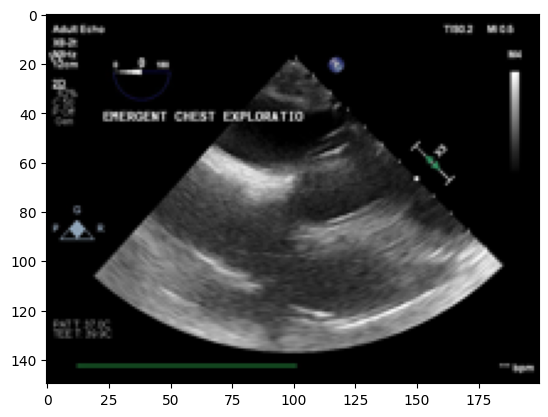

In [8]:
plt.imshow(inference[0][0].permute(1,2,0))

In [9]:
# Creating the model

# efnet_model = models.efficientnet_v2_m(num_classes=len(class_names), dropout=0.2)  # medium model
efnet_model = models.efficientnet_v2_l(num_classes=len(class_names), dropout=0.2)  # large model


efnet_model = efnet_model.to(device)
efnet_model.eval()
efnet_model.load_state_dict(torch.load('../../experiments/multiclass_view_model_00.pt', map_location=device))
multiclass_model = efnet_model

In [10]:
def evaluate_multiclass_model_clipwise(model, test_dataset, increment=5, topk=1):
    was_training = model.training
    model.eval()

    predictions = []
    clip_labels = []
    subjet_labels = []
    
    with torch.no_grad():
        for i, inputs in tqdm.tqdm(enumerate(test_dataset), total=len(test_dataset)):
            if i%increment!=0:
                continue
            clip_labels.append(inputs[1])
            subjet_labels.append(inputs[2])
            
            image = torch.unsqueeze(inputs[0], dim=0).to(device)
            outputs = model(image)
            predictions.append(outputs[0,:].cpu().numpy())

    aggregate_predictions = []
    aggregate_labels = []
    running_sum = np.zeros(len(class_names))
    current_clip = clip_labels[0]
    for clip_label in clip_labels:
        if current_clip != clip_label:
            aggregate_predictions.append(running_sum)
            aggregate_labels.append(current_clip)
            running_sum = np.zeros(len(class_names))
            current_clip = clip_label
        else:
            running_sum += predictions[clip_labels.index(clip_label)]
        
    if topk == 1:
        test_labels_predicted = np.argmax(aggregate_predictions,axis=1)
    else:
        test_labels_predicted = np.argsort(aggregate_predictions,axis=1)[:,-topk:]
    
    return np.array(aggregate_predictions), np.array(test_labels_predicted), aggregate_labels

In [11]:
# Evaluate multiclass model

def class_2_index(class_name, class_names):
    indices = np.where(np.array(class_names)==class_name)
    return np.eye(len(class_names))[indices]

results_compiled = []

test_predictions, test_labels, clip_paths = evaluate_multiclass_model_clipwise(multiclass_model, inference, increment=10, topk=1)

100%|██████████| 541446/541446 [27:13<00:00, 331.46it/s]


In [12]:
results = pd.DataFrame({'clip_path':clip_paths, 'prediction':test_labels})
os.makedirs(f'cyclic_labeling/cycle_{str(cycle).zfill(2)}', exist_ok=True)
results.to_csv(f'cyclic_labeling/cycle_{str(cycle).zfill(2)}/predictions_cycle_{str(cycle).zfill(2)}.csv', index=False)

(array([ 611.,  117.,  500.,  127.,  866.,  302.,  312.,   87.,   87.,
         234.,  302.,  210.,  245.,  306.,  206.,  175.,  329.,  439.,
         204.,   41.,  120.,  157., 2213.,  174.,  637.]),
 array([ 0.  ,  1.04,  2.08,  3.12,  4.16,  5.2 ,  6.24,  7.28,  8.32,
         9.36, 10.4 , 11.44, 12.48, 13.52, 14.56, 15.6 , 16.64, 17.68,
        18.72, 19.76, 20.8 , 21.84, 22.88, 23.92, 24.96, 26.  ]),
 <BarContainer object of 25 artists>)

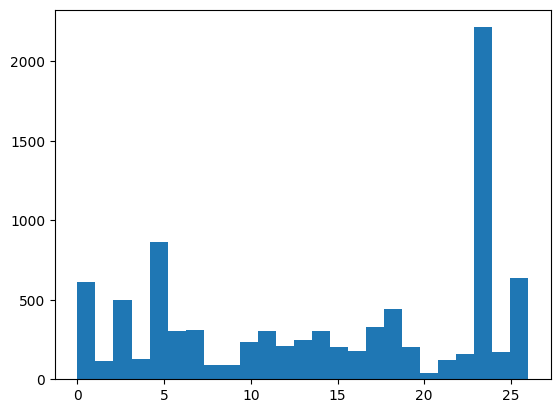

In [13]:
plt.hist(test_labels, bins=25)

In [14]:
rows = 10
cols = 10

for id, view in tqdm.tqdm(enumerate(class_names)):
    print(view)
    os.makedirs(f'cyclic_labeling/cycle_{str(cycle).zfill(2)}/{view}', exist_ok=True)
    for page in range(len(results.loc[results['prediction']==id]['clip_path'])//rows + 1):
        fig, ax = plt.subplots(rows, cols, figsize=(20,rows * 2))
        for i, clip_path in enumerate(list(results.loc[results['prediction']==id]['clip_path'])[page * rows:]):
            images = glob.glob(clip_path+'/*.png')

            indices = sorted(list(torch.randint(len(images), size=(cols,))))
            indices = indices
            for j, index in enumerate(indices):
                ax[i, j].imshow(np.array(Image.open(images[index])))
                ax[i, j].axis('off')
            ax[i, 2].set_title(f'\n{clip_path}', x = 3)
            if i == rows-1:
                break
        fig.suptitle(f'{view}  page {page}', y=.1)
        
        plt.savefig(f'cyclic_labeling/cycle_{str(cycle).zfill(2)}/{view}/page_{str(page).zfill(3)}.jpg', dpi=300)
        plt.close()
    results.loc[results['prediction']==id].to_csv(f'cyclic_labeling/cycle_{str(cycle).zfill(2)}/{view}__cycle_{str(cycle).zfill(2)}.csv', index=False)

0it [00:00, ?it/s]

deep_tg_col_a


1it [01:26, 86.26s/it]

dta_sax


2it [02:16, 65.28s/it]

...

25it [30:18, 124.93s/it]

tg_mid_pap_sax


26it [32:52, 133.79s/it]

ue_asc_ao_sax


27it [33:13, 73.83s/it] 


# Grow the dataset

In [1]:
import pandas as pd

import sys
sys.path.append('..')
import re
import os
import random
import numpy as np
from PIL import Image
from natsort import natsorted
import glob
import shutil
import tqdm

In [8]:
save_dir = '/home/trevor/repos/deep_TEE/data/semi-processed/supervised/growing_multiview_training/me_2_ch_col_m'
# os.makedirs(save_dir, exist_ok=True)
# import shutil

In [9]:
predictions = pd.read_csv(f'/home/trevor/repos/deep_TEE/labels/cyclic_view_labeling/new_labels/me_2_ch_col_m__cycle_03_RG.csv')

In [11]:
paths = list(predictions.loc[predictions['Unnamed: 2']=='y']['clip_path'])
print(len(paths))

114


In [12]:
for path in tqdm.tqdm(paths):
    for img in glob.glob(path+'/*.png'):
        # print(os.path.join(save_dir, os.path.splitext(path)[0].split('/')[-1]) + '_' + img.split('/')[-1])
        shutil.copy(img, os.path.join(save_dir, os.path.splitext(path)[0].split('/')[-1]) + '_' + img.split('/')[-1])

100%|██████████| 114/114 [00:01<00:00, 78.79it/s]


In [14]:
# for clip_path in tqdm.tqdm(predictions.loc[predictions['Unnamed: 2']=='y']['clip_path']):
#     print(os.path.join(save_dir, clip_path.split('/')[-1]))
#     # break
#     # shutil.copytree(clip_path, os.path.join(save_dir, clip_path.split('/')[-1]), dirs_exist_ok=True)

In [15]:
# for img in tqdm.tqdm(glob.glob(os.path.join(save_dir, '**/*.png'), recursive=True)):
#     image = np.array(Image.open(img))
#     image = image[11:139,38:166]
#     if image.shape[0] != 128 or image.shape[1] != 128:
#         continue
#     Image.fromarray(image).save(img)